# Clustering, cell type annotation and reference mapping

*Python port of the R vignette [Clustering, cell type annotation and reference mapping](https://gregorlueg.github.io/bixverse/articles/cell_type_annotation.html). Original author: Gregor Lueg.*

## Intro

Getting from a corrected embedding to cell type labels involves more choices
than a single `find_clusters()` call suggests. Which graph do you cluster on?
Leiden or Louvain, and how many iterations? Do you cluster every cell, or
coarsen first because you have a million of them? Do you stamp one label per
cluster, or score each cell? And once you have a well annotated data set, how
do you avoid redoing all of it every time a new sample lands on your desk?

This vignette goes through these decisions in that order:

1. Build a reference from two PBMC data sets (pbmc3k + pbmc4k), corrected
   with Harmony v2.
2. Compare the three neighbour graphs bixverse can build (sNN, the UMAP fuzzy
   simplicial set and the plain kNN union) and what they do to the clustering.
3. Leiden vs Louvain, and the fast clustering via k-means coarsening.
4. Annotate with scType, per cluster and per cell.
5. Compress the reference with Symphony
   ([Kang, et al., 2021](https://doi.org/10.1038/s41467-021-25957-x)), map a
   third PBMC data set (pbmc8k) into it and transfer the labels.

If you have not read the
[batch correction vignette](single_cell_batch_corrections.ipynb) and the
[introductory vignette](thinking_single_cell.ipynb), please do so first; this
vignette assumes familiarity with both.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import FastClusterParams, HarmonyV2Params, NeighboursParams

## Building the reference data

### Loading the reference batches

We use the same pbmc3k + pbmc4k pair as in the batch correction vignette. Two
batches with the same broad cell type composition and a clear technical
difference between them is exactly the situation Symphony is designed for:
the reference learns the batch correction once, and that correction can then
be applied to future queries without rerunning Harmony.

In [2]:
dir_data = bv.io.download_pbmc_batches()

tempdir_ref = tempfile.TemporaryDirectory()

h5ad_paths = {
    "pbmc3k": dir_data / "pbmc3k.h5ad",
    "pbmc4k": dir_data / "pbmc4k.h5ad",
}

h5_tasks = bv.io.prescan_h5ad_files(h5ad_paths)

sc_ref = bv.io.load_multi_h5ad(
    Path(tempdir_ref.name) / "symphony_ref",
    h5_tasks,
    verbose=True,
)

sc_ref

Scan 1/2: Counting gene expression across 2 files...
  Scanning genes in pbmc3k...
  Scanning genes in pbmc4k...
  Genes passing global QC: 13_925 / 31_232
Scan 2/2: Computing cell QC with final gene set...
  Scanning cells in pbmc3k...
  Scanning cells in pbmc4k...
  pbmc3k: 2_700 / 2_700 cells passing QC
  pbmc4k: 4_340 / 4_340 cells passing QC
  Total cells: 7_040
Writing cells to binary...
  Writing pbmc3k (2_700 cells)...
  Writing pbmc4k (4_340 cells)...
Multi-h5ad loading complete: 175.19ms
  Counted 7_889_186 non-zeros over 13_925 genes in 3.16ms; converting in 1 phase(s).


  Phase 1/1: genes 0-13925, scatter 14.68ms, compress + write 55.29ms
  Conversion into gene-friendly format done: 73.96ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpkp_duxkn/symphony_ref',
  cells=7040 (kept 7040), genes=13925,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

### Quality control

Standard QC: mitochondrial gene proportions, library complexity, MAD-based
outlier detection.

In [3]:
# the gene symbols come from one of the h5ad files: the multi file import
# keeps only gene_id in var
h5_metadata = bv.io.read_h5ad_metadata(h5ad_paths["pbmc3k"])

var_ref = sc_ref.var().join(
    h5_metadata["var"].select("gene_id", pl.col("symbol_tenx").alias("gene_symbol")),
    on="gene_id",
)

gs_of_interest = {
    "MT": var_ref.filter(pl.col("gene_symbol").str.contains("^MT-"))[
        "gene_id"
    ].to_list(),
    "Ribo": var_ref.filter(pl.col("gene_symbol").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}

bv.qc.gene_set_proportions(sc_ref, gs_of_interest, streaming=False, verbose=True)

qc_df = sc_ref.obs(cols=["cell_id", "lib_size", "nnz", "MT", "exp_id"])

qc = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
        "MT": qc_df["MT"].to_numpy(),
    },
    sc_ref.cells_to_keep,
    directions={
        "log10_lib_size": "twosided",
        "log10_nnz": "twosided",
        "MT": "above",
    },
    threshold=3.0,
)

sc_ref.add_obs(pl.DataFrame({"cell_idx": qc.cell_idx, "outlier": qc.combined}))
sc_ref.set_cells_to_keep(qc.cell_idx[~qc.combined])

print(f"{qc.combined.sum()} of {qc.combined.size} cells flagged")

Load in data: 6.78ms
Finished the gene set proportion calculations: 1.94ms


414 of 7040 cells flagged


### HVGs, PCA, Harmony v2

This block is the Harmony v2 path of the batch correction vignette: pick HVGs,
run PCA, run Harmony v2. Version 1 is still available via
`bv.integrate.harmony()` and `HarmonyParams`, but v2 is preferable in most
settings (see the batch correction vignette for the reasoning).

In [4]:
bv.pp.find_hvg(sc_ref, hvg_no=2000, verbose=True)

bv.pp.calculate_pca(sc_ref, no_pcs=30)

bv.integrate.harmony_v2(sc_ref, "exp_id", harmony_params=HarmonyV2Params())

HVG (VST): 13_925 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 7.60ms
HVG (VST): Fitted Loess in 544.04µs
HVG (VST): Standardised variance in 812.92µs (690 gene(s) re-read for the clip)
HVG (VST): Total run time -> 9.00ms


## Which graph to cluster on

`find_neighbours()` does two things: it finds the kNN on the embedding and it
symmetrises that kNN into the undirected, weighted graph the clustering runs
on. The second step is controlled by `knn_sym` in `NeighboursParams`. Three
options:

- `"snn"` (default): the shared nearest neighbour graph of bluster/Seurat. Two
  cells are linked if their neighbourhoods overlap, weighted by Jaccard (or
  rank), and weak edges below `pruning` are dropped.
- `"umap"`: the fuzzy simplicial set from UMAP, i.e. what ScanPy stores in
  `obsp/connectivities`. Use this if you want your Leiden clusters to line up
  with a ScanPy pipeline.
- `"knn"`: the plain union of the kNN, every edge weighted 1.

Let's build all three on the Harmony embedding and cluster each across a few
resolutions. Every call recomputes the kNN as well, which at ~6k cells costs
nothing.

In [5]:
graph_types = ["snn", "umap", "knn"]
resolutions = [0.5, 1.0, 1.5, 2.0]

rows = []
for graph_type in graph_types:
    bv.graph.find_neighbours(
        sc_ref,
        embd_to_use="harmony_v2",
        neighbours_params=NeighboursParams(knn_sym=graph_type),
    )
    for res in resolutions:
        col_name = f"leiden_{graph_type}_{res}"
        bv.graph.find_clusters(sc_ref, res=res, name=col_name)
        n = sc_ref.obs(cols=[col_name], filtered=True)[col_name].n_unique()
        rows.append({"graph": graph_type, "resolution": res, "n_clusters": n})

n_clusters = pl.DataFrame(rows)

n_clusters.pivot("graph", index="resolution", values="n_clusters")

resolution,snn,umap,knn
f64,i64,i64,i64
0.5,12,12,9
1.0,17,15,14
1.5,20,20,17
2.0,21,25,21


The point of this table: **resolutions do not carry over between graphs**. The
`"umap"` and `"knn"` graphs only hold the kNN pairs, while the sNN graph also
links cells that merely share neighbours and prunes weak edges. On this data
the differences are a handful of communities at a given resolution, and not
always in the same direction. On other data they can be larger. If you move a
ScanPy pipeline over and switch to `knn_sym="umap"`, keep its resolution; if
you switch to sNN, retune it.

For the rest of the vignette we work on the sNN graph.

In [6]:
bv.graph.find_neighbours(
    sc_ref,
    embd_to_use="harmony_v2",
    neighbours_params=NeighboursParams(),
)

bv.embed.umap(sc_ref, embd_to_use="harmony_v2", slot_name="umap_harm_v2")

## Clustering

### Leiden vs Louvain

Both run in Rust, and the labels depend on `seed` only, not on the global RNG
or the number of threads. Leiden is the default; it guarantees connected
communities, which Louvain does not
([Traag, et al., 2019](https://www.nature.com/articles/s41598-019-41695-z)).
Labels are 0-based with `0` being the largest cluster.

In [7]:
bv.graph.find_clusters(sc_ref, res=1.0, name="leiden_clusters")

bv.graph.find_clusters(
    sc_ref,
    cluster_algorithm="louvain",
    res=1.0,
    name="louvain_clusters",
)

A few knobs on `find_clusters()`:

- `n_iterations`: defaults to `2` for Louvain and `5` for Leiden. A negative
  value iterates until the partition is stable.
- `min_gain`: with a negative `n_iterations`, also stop once an iteration gains
  no more than this in modularity.
- `local_moving`: `"queue"` is Traag's sequential queue, `"coloured"` moves the
  nodes of one colour class in parallel. The latter only kicks in on the
  larger levels of the graph, so on 6k cells don't expect much.

In [8]:
bv.graph.find_clusters(
    sc_ref,
    res=1.0,
    name="leiden_stable",
    n_iterations=-1,
    min_gain=1e-4,
    local_moving="coloured",
)

How much do the three labelings agree? A small helper that plots, for each
cluster of one labeling, how its cells spread across the clusters of another:

In [9]:
def plot_overlap(a, b, name_a, name_b, title):
    df = (
        pl.DataFrame({"a": a, "b": b})
        .group_by("a", "b")
        .len()
        .with_columns(frac=pl.col("len") / pl.col("len").sum().over("a"))
    )
    a_levels = np.sort(df["a"].unique().to_numpy())
    b_levels = np.sort(df["b"].unique().to_numpy())
    mat = np.full((a_levels.size, b_levels.size), np.nan)
    ai = np.searchsorted(a_levels, df["a"].to_numpy())
    bi = np.searchsorted(b_levels, df["b"].to_numpy())
    mat[ai, bi] = df["frac"].to_numpy()

    fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
    im = ax.imshow(mat, cmap="viridis", vmin=0, vmax=1, origin="lower", aspect="auto")
    # light text on the dark end of viridis, dark text on the yellow end
    for i, j, f in zip(ai, bi, df["frac"].to_numpy(), strict=True):
        ax.text(
            j,
            i,
            f"{f:.2f}",
            ha="center",
            va="center",
            fontsize=6,
            color="white" if f < 0.5 else "black",
        )
    ax.set_xticks(range(b_levels.size), b_levels)
    ax.set_yticks(range(a_levels.size), a_levels)
    ax.set_xlabel(name_b)
    ax.set_ylabel(name_a)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label="Fraction")
    return ax

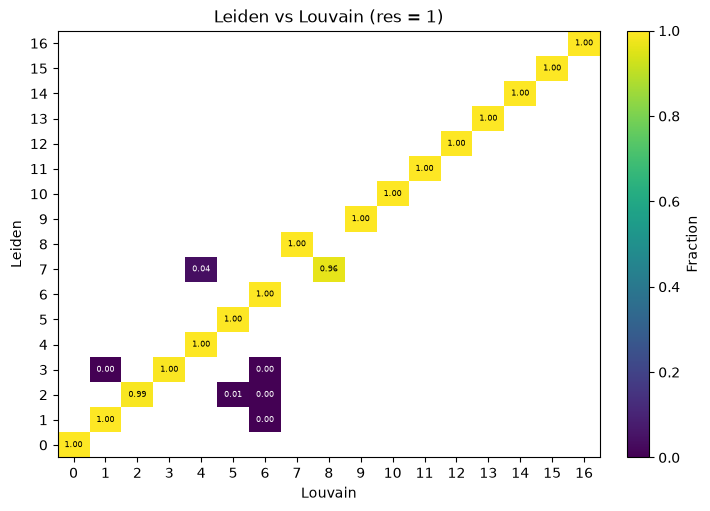

In [10]:
clusters_df = sc_ref.obs(
    cols=["leiden_clusters", "louvain_clusters", "leiden_stable"], filtered=True
)

plot_overlap(
    clusters_df["leiden_clusters"],
    clusters_df["louvain_clusters"],
    "Leiden",
    "Louvain",
    "Leiden vs Louvain (res = 1)",
)
plt.show()

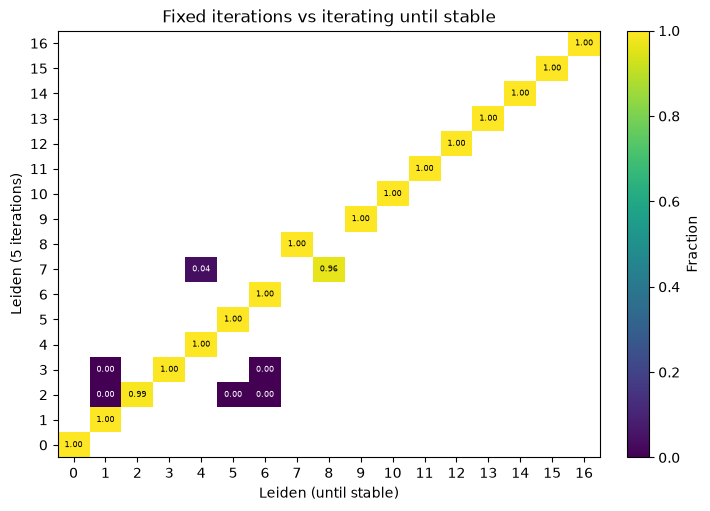

In [11]:
plot_overlap(
    clusters_df["leiden_clusters"],
    clusters_df["leiden_stable"],
    "Leiden (5 iterations)",
    "Leiden (until stable)",
    "Fixed iterations vs iterating until stable",
)
plt.show()

### Fast clustering

On a few thousand cells the full graph clustering is instant. On a million it
isn't. `fast_cluster()` coarsens the cells with k-means first
(`floor(4 * sqrt(N))` centroids by default, the faiss default for IVF), builds
a graph over the centroids and runs Louvain or Leiden on that. Each cell
inherits the community of its centroid. Two options for the centroid graph:

- the default, a symmetrised kNN between the centroids (`centroid_k`,
  `knn_sym`);
- `cell_mediated=True`, the Secuer graph (Wei, et al., PLoS Comput Biol,
  2022), where each cell links its `n_anchors` nearest centroids, so two
  centroids are connected if they share cells.

With `n_seeds > 1` every resolution is run once per seed. The labels of the
seed with the lowest mean conductance are kept, and the ARI and conductance
across seeds come back as stability statistics.

In [12]:
fc_resolutions = (2.0, 1.5, 1.0, 0.5)

fc_knn = bv.graph.fast_cluster(
    sc_ref,
    embd_to_use="harmony_v2",
    resolutions=fc_resolutions,
    n_seeds=10,
)

fc_cell_med = bv.graph.fast_cluster(
    sc_ref,
    embd_to_use="harmony_v2",
    resolutions=fc_resolutions,
    fc_params=FastClusterParams(cell_mediated=True),
    n_seeds=10,
)

The stats help to pick a resolution: high ARI means the partition barely
changes between seeds, low conductance means the communities are well
separated in the centroid graph.

In [13]:
fc_stats = pl.concat(
    [
        fc_knn.stats.with_columns(graph=pl.lit("centroid kNN")),
        fc_cell_med.stats.with_columns(graph=pl.lit("cell-mediated")),
    ]
)

fc_stats

resolution,mean_ari,median_ari,mean_conductance,median_conductance,mean_n_comms,graph
f64,f64,f64,f64,f64,f64,str
2.0,0.914961,0.912967,0.23121,0.185981,7.7,"""centroid kNN"""
1.5,0.99175,0.985151,0.059546,0.063425,5.0,"""centroid kNN"""
1.0,0.998699,1.0,0.05632,0.063209,5.0,"""centroid kNN"""
0.5,1.0,1.0,0.056174,0.062939,5.0,"""centroid kNN"""
2.0,0.906479,0.896223,0.202286,0.164447,12.7,"""cell-mediated"""
1.5,0.905134,0.87862,0.170314,0.148429,11.6,"""cell-mediated"""
1.0,0.920831,0.919009,0.143469,0.128804,9.9,"""cell-mediated"""
0.5,0.931444,0.973917,0.071501,0.060159,5.9,"""cell-mediated"""


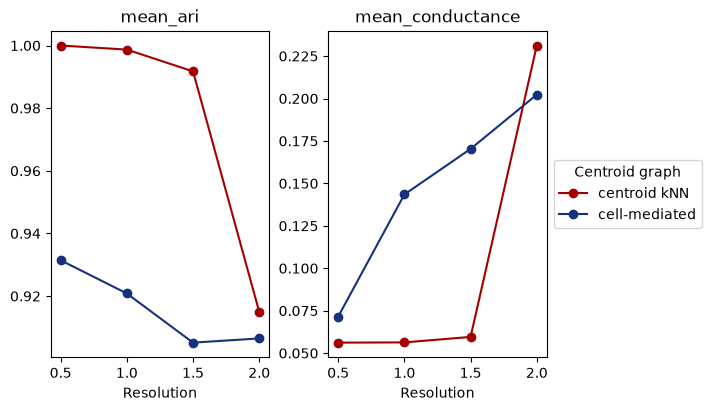

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7, 4), layout="constrained")
graphs = ["centroid kNN", "cell-mediated"]
colours = bv.pl.bx_colors("main", n=len(graphs))
for ax, metric in zip(axes, ["mean_ari", "mean_conductance"], strict=True):
    for graph, colour in zip(graphs, colours, strict=True):
        df = fc_stats.filter(pl.col("graph") == graph).sort("resolution")
        ax.plot(df["resolution"], df[metric], marker="o", color=colour, label=graph)
    ax.set_title(metric)
    ax.set_xlabel("Resolution")
axes[1].legend(title="Centroid graph", loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

And how does the coarsened version compare against Leiden on the full graph?

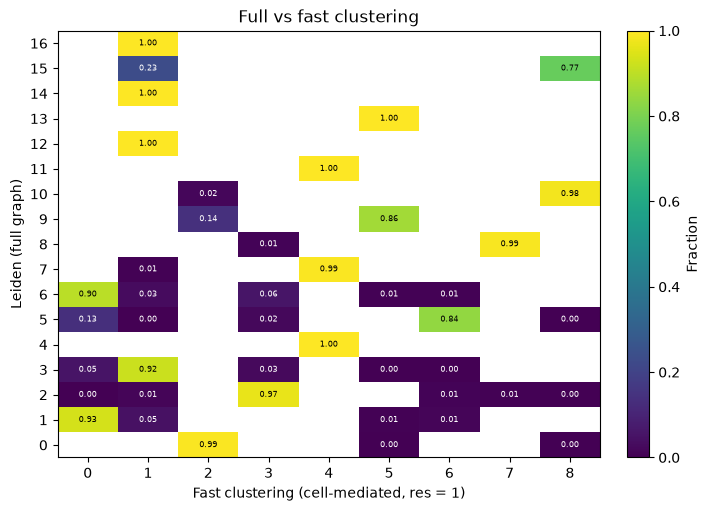

In [15]:
sc_ref.add_obs(fc_cell_med.memberships)

fast_df = sc_ref.obs(cols=["leiden_clusters", "res_1"], filtered=True)

plot_overlap(
    fast_df["leiden_clusters"],
    fast_df["res_1"],
    "Leiden (full graph)",
    "Fast clustering (cell-mediated, res = 1)",
    "Full vs fast clustering",
)
plt.show()

The numbers behind the plot:

In [16]:
n_cells_ref = sc_ref.n_cells
print(f"cells: {n_cells_ref}, centroids: {int(4 * np.sqrt(n_cells_ref))}")
print(f"Leiden (full graph), res = 1: {fast_df['leiden_clusters'].n_unique()}")
print(f"fast clustering (cell-mediated), res = 1: {fast_df['res_1'].n_unique()}")

cells: 6626, centroids: 325
Leiden (full graph), res = 1: 17
fast clustering (cell-mediated), res = 1: 9


With a few hundred centroids the partition comes out coarser than Leiden on
the full graph at the same resolution, and the centroid boundaries cut through
some of the full graph communities. For data sets of this size, stick with
`find_clusters()`. The fast path earns its keep once you are in the hundreds
of thousands of cells, see the
[1 million cells vignette](single_cell_big_data.ipynb).

## Cell type annotation

### scType per cluster

We annotate with scType (Ianevski, et al., Nat Comm, 2022) using a PBMC
marker set.

In [17]:
cell_markers = {
    "CD3D": "T cells",
    "CD3E": "T cells",
    "CD3G": "T cells",
    "IL7R": "CD4+ T",
    "CD4": "CD4+ T",
    "CD8A": "CD8+ T",
    "CD8B": "CD8+ T",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD19": "B cells",
    "CD14": "CD14+ Mono",
    "LYZ": "CD14+ Mono",
    "S100A8": "CD14+ Mono",
    "FCGR3A": "CD16+ Mono",
    "CDKN1C": "CD16+ Mono",
    "GNLY": "NK",
    "NKG7": "NK",
    "NCAM1": "NK",
    "FCER1A": "mDC",
    "CD1C": "mDC",
    "LILRA4": "pDC",
    "CLEC4C": "pDC",
    "PPBP": "Platelet",
    "PF4": "Platelet",
}

`calc_sc_type_scores()` scores every cell against every marker set,
`score_clusters()` sums the scores per cluster and assigns the winner.

In [18]:
cell_markers_df = pl.DataFrame(
    {"gene_symbol": list(cell_markers), "cell_type": list(cell_markers.values())}
).join(var_ref.select("gene_symbol", "gene_id"), on="gene_symbol")

marker_list = bv.annotate.prepare_cell_markers(sc_ref, cell_markers_df)

sctype_scores = bv.annotate.calc_sc_type_scores(sc_ref, marker_list)

leiden = sc_ref.obs(cols=["leiden_clusters"], filtered=True)["leiden_clusters"]

cell_type_anno = bv.annotate.score_clusters(sctype_scores, leiden.to_numpy())

sc_ref.add_obs(
    sc_ref.obs(cols=["cell_idx", "leiden_clusters"], filtered=True)
    .join(
        cell_type_anno.select(
            pl.col("cluster_id").alias("leiden_clusters"),
            pl.col("cell_type").alias("sc_type"),
        ),
        on="leiden_clusters",
        how="left",
    )
    .select("cell_idx", "sc_type")
)

cell_type_anno

cluster_id,cell_type,scores,n_cells
i32,str,f64,i32
0,"""CD14+ Mono""",3417.550049,1100
1,"""T cells""",989.798706,1046
2,"""CD8+ T""",1084.44458,871
3,"""T cells""",838.502747,806
4,"""B cells""",1947.019043,596
…,…,…,…
12,"""T cells""",26.300388,29
13,"""Platelet""",393.636444,26
14,"""T cells""",15.531169,25


### scType per cell

The cluster level call stamps one label on every cell of a cluster. A small
population that shares a Leiden community with a bigger one gets absorbed and
nothing flags it. `assign_sc_type()` scores per cell instead: the score matrix
is smoothed over the neighbour graph via label spreading (Zhou, et al., NIPS,
2004), then each cell takes its own argmax. Cells whose best score falls below
`score_floor` come back as null. Pass `cluster_col` and you also get the
per-cluster composition and a hybrid call: clusters at or above
`purity_threshold` keep the cluster level label, mixed clusters fall back to
the per-cell calls.

In [19]:
sctype_cells = bv.annotate.assign_sc_type(
    sc_ref,
    sctype_scores,
    cluster_col="leiden_clusters",
)

sc_ref.add_obs(
    pl.DataFrame(
        {
            "cell_idx": sc_ref.cells_to_keep,
            "sc_type_cell": sctype_cells.assignments,
            "sc_type_hybrid": sctype_cells.hybrid,
            "sc_type_margin": sctype_cells.margins,
        }
    )
)

sctype_cells

ScTypeCellResults: 6626 cells, 10 cell types
  Unknown cells:  69
  Smoothing used: TRUE
  Mixed clusters: 9 out of 17

The composition table is the place to look for clusters that hide more than
one cell type. The mixed ones:

In [20]:
sctype_cells.composition.filter(pl.col("cluster_mixed")).select(
    "cluster_id", "n_cells", "dominant", "purity", "second", "second_fraction"
)

cluster_id,n_cells,dominant,purity,second,second_fraction
i32,i32,str,f64,str,f64
1,1046,"""T cells""",0.755258,"""CD4+ T""",0.17782
2,871,"""CD8+ T""",0.424799,"""NK""",0.280138
3,806,"""T cells""",0.636476,"""CD4+ T""",0.307692
5,534,"""CD8+ T""",0.872659,"""T cells""",0.11236
6,423,"""T cells""",0.624114,"""CD4+ T""",0.125296
12,29,"""T cells""",0.689655,"""CD4+ T""",0.275862
14,25,"""T cells""",0.4,"""CD8+ T""",0.24
15,13,"""Platelet""",0.461538,"""CD4+ T""",0.153846
16,10,"""mDC""",0.8,"""CD4+ T""",0.2


Most of the mixed clusters are T cell clusters split between `"T cells"` and
`"CD4+ T"` or `"CD8+ T"`. That is the marker set, not the method: the generic
`"T cells"` set (CD3D/E/G) competes with the subtype sets on the same cells. A
hierarchical marker set, or dropping the generic T cell entry, cleans this up.

The margin (best minus second best score) flags ambiguous calls:

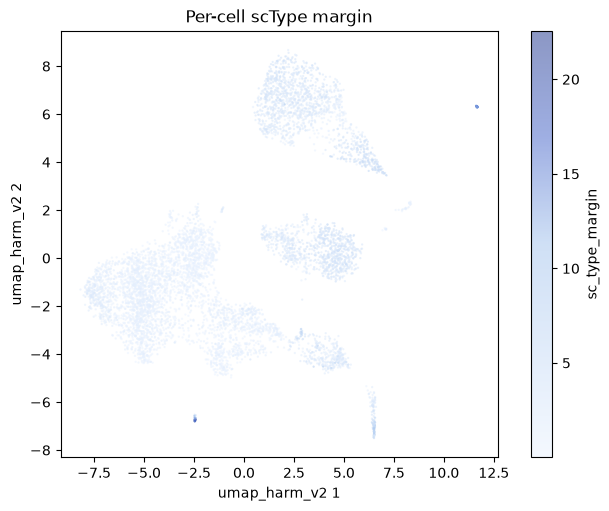

In [21]:
ax = bv.pl.embedding_plot(
    sc_ref,
    "umap_harm_v2",
    "sc_type_margin",
    discrete=False,
)
ax.set_title("Per-cell scType margin")
plt.show()

### Sanity checks

Batches mixed, cell types separated:

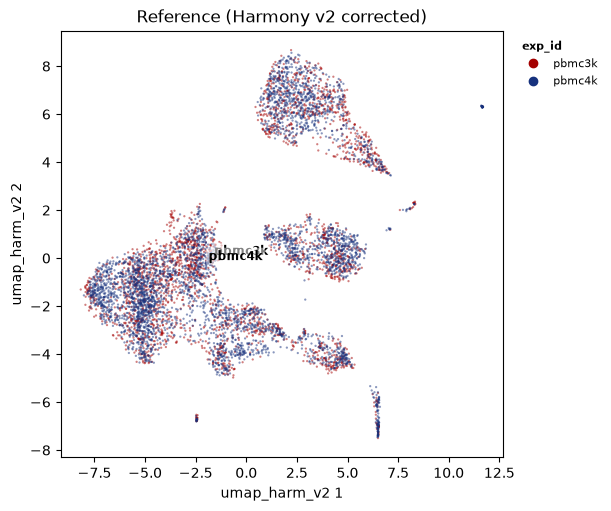

In [22]:
ax = bv.pl.embedding_plot(
    sc_ref,
    "umap_harm_v2",
    "exp_id",
    label_by="exp_id",
    discrete=True,
)
ax.set_title("Reference (Harmony v2 corrected)")
plt.show()

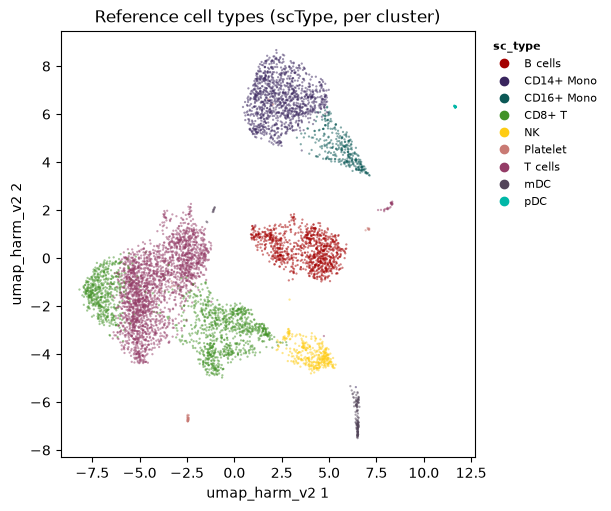

In [23]:
ax = bv.pl.embedding_plot(sc_ref, "umap_harm_v2", "sc_type", discrete=True)
ax.set_title("Reference cell types (scType, per cluster)")
plt.show()

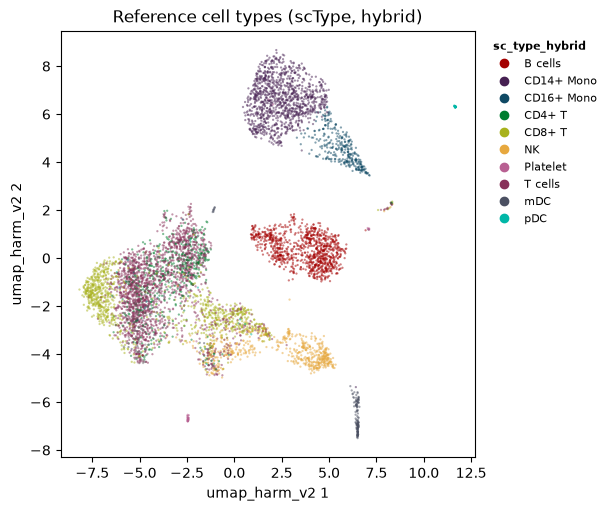

In [24]:
ax = bv.pl.embedding_plot(sc_ref, "umap_harm_v2", "sc_type_hybrid", discrete=True)
ax.set_title("Reference cell types (scType, hybrid)")
plt.show()

And the canonical markers:

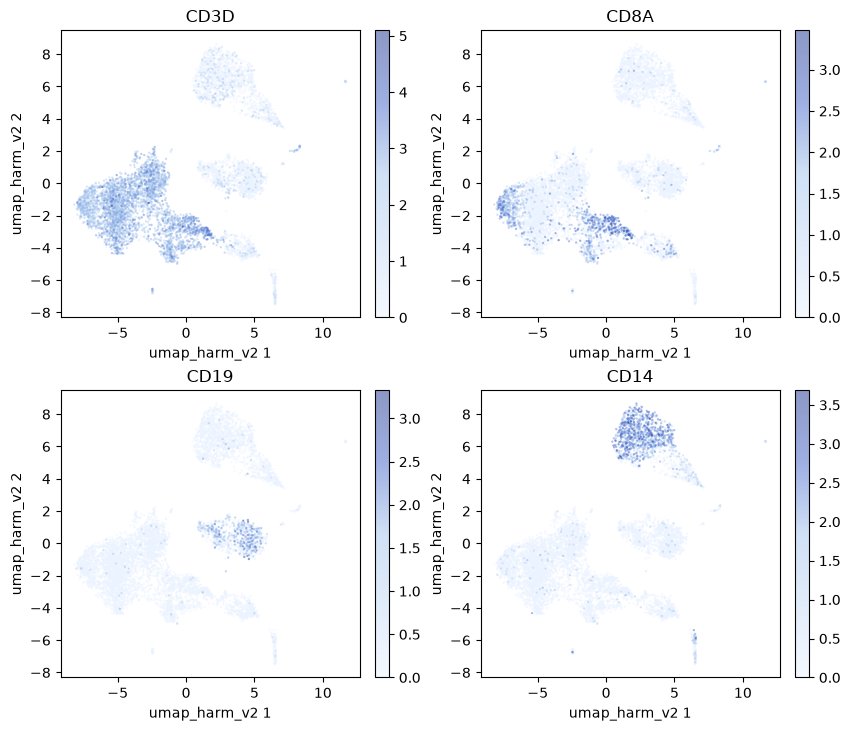

In [25]:
canonical_markers = {
    "ENSG00000167286": "CD3D",
    "ENSG00000153563": "CD8A",
    "ENSG00000177455": "CD19",
    "ENSG00000170458": "CD14",
}

bv.pl.feature_plot(
    sc_ref,
    list(canonical_markers),
    "umap_harm_v2",
    feature_labels=canonical_markers,
)
plt.show()

## Reference mapping with Symphony

Once you have a well annotated reference, you don't want to redo QC, HVG
selection, PCA, batch correction, clustering and manual annotation for every
new sample. Symphony compresses the reference into a small set of cached terms
that map new query cells into the same coordinate system in a single shot,
with no need to keep the reference cells around at query time.

### Compressing into a SymphonyReference

`build_symphony_ref()` re-runs PCA and Harmony internally using the supplied
HVGs, then caches the loadings, centroids and compression terms (`nr`,
`c_cache`) needed for query mapping. The Harmony version follows the type of
`harmony_params`. Pass `label_columns` to snapshot one or more obs columns,
here both scType annotations, into the reference for downstream label
transfer.

A note on the apparent duplication: yes, PCA + Harmony are run again inside
`build_symphony_ref()`, even though we just ran them on the same HVGs above.
This is deliberate. The standard pipeline keeps its embeddings on the
`SingleCells` object and streams from disk; the Symphony reference keeps a
self-contained, in-memory copy of everything it needs to project queries
without the reference cells. Sharing state across those two representations
would tie them together in unhelpful ways. The cost is one extra PCA + Harmony
run at build time.

In [26]:
# 0-based HVG indices, as stored on the experiment
hvg_indices = sc_ref.map.hvg

symphony_ref = bv.annotate.build_symphony_ref(
    sc_ref,
    "exp_id",
    hvg_indices,
    harmony_params=HarmonyV2Params(),
    no_pcs=30,
    label_columns=["sc_type", "sc_type_hybrid"],
    verbose=True,
)

symphony_ref

Symphony: building reference
Sparse PCA: Loaded in data in 9.77ms
Sparse PCA: finished the data preparations in 1.31ms


Sparse PCA: finished calculations in 239.49ms
Sparse PCA: total run time -> 250.69ms
Harmony v2: 6_626 cells, 30 dims, 1 variable(s), 100 clusters
  Variable 0: 2 levels
 Initial data preparation done in 344.00µs
Running initial k-means...
Initial objective: 354.8765

=== Harmony v2 iteration 1 ===
  Running k-means clustering...
  Applying ridge regression correction...
  Harmony objective: 335.7882
   Finished iteration in 3.92ms / Total runtime 12.17ms

=== Harmony v2 iteration 2 ===
  Running k-means clustering...
  Applying ridge regression correction...
  Harmony objective: 220.0640
   Finished iteration in 3.89ms / Total runtime 16.08ms

=== Harmony v2 iteration 3 ===
  Running k-means clustering...
  Applying ridge regression correction...
  Harmony objective: 142.1761
   Finished iteration in 3.66ms / Total runtime 19.74ms

=== Harmony v2 iteration 4 ===
  Running k-means clustering...
  Applying ridge regression correction...
  Harmony objective: 117.6671
   Finished iteratio

Symphony reference
  Harmony backend: v2
  No HVGs: 2000
  No PCs: 30
  No clusters: 100
  Batch variables: exp_id
  Slim: FALSE
  Labels: sc_type, sc_type_hybrid

The repr tells you the Harmony backend, the size of the loadings and centroid
matrices, the batch variables and the stored label columns.

### Loading the query

We use pbmc8k as the query. Same tissue, same broad biology, but a different
10x run: exactly the kind of "another sample arrives" scenario Symphony is
built for.

In [27]:
pbmc8k_path = bv.io.download_pbmc8k()

tempdir_query = tempfile.TemporaryDirectory()

sc_query = bv.io.load_mtx(
    Path(tempdir_query.name) / "symphony_query",
    bv.io.get_cell_ranger_params(pbmc8k_path),
    verbose=True,
)

sc_query

Text pass (integer): 2 buckets, ~4191 cells/bucket
Text pass done: 92.63ms (cell-major order)
Genes passing QC: 15_446 / 33_694
Cells passing QC: 8_381 / 8_381
Writing pass: 2 buckets, no sort


  Wrote bucket 1/2 (50%)
  Wrote bucket 2/2 (100%)
Writing pass done: 109.31ms


  Counted 11_768_954 non-zeros over 15_446 genes in 5.39ms; converting in 1 phase(s).
  Phase 1/1: genes 0-15446, scatter 15.22ms, compress + write 65.41ms
  Conversion into gene-friendly format done: 88.70ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpici0yjbl/symphony_query',
  cells=8381 (kept 8381), genes=15446,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

### Quality control on the query

Same QC as the reference. We are not trying to match library sizes or anything
fancy across data sets, just remove clearly bad cells.

In [28]:
var_q = sc_query.var()

gs_q = {
    "MT": var_q.filter(pl.col("column1").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var_q.filter(pl.col("column1").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}

bv.qc.gene_set_proportions(sc_query, gs_q, streaming=False, verbose=True)

qc_df_q = sc_query.obs(cols=["cell_id", "lib_size", "nnz", "MT"])

qc_q = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df_q["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df_q["nnz"].to_numpy()),
        "MT": qc_df_q["MT"].to_numpy(),
    },
    sc_query.cells_to_keep,
    directions={
        "log10_lib_size": "twosided",
        "log10_nnz": "twosided",
        "MT": "above",
    },
    threshold=3.0,
)

sc_query.add_obs(pl.DataFrame({"cell_idx": qc_q.cell_idx, "outlier": qc_q.combined}))
sc_query.set_cells_to_keep(qc_q.cell_idx[~qc_q.combined])

print(f"{qc_q.combined.sum()} of {qc_q.combined.size} cells flagged")

Load in data: 9.37ms
Finished the gene set proportion calculations: 2.51ms


507 of 8381 cells flagged


### Projecting the query

`map_symphony_query()` does the actual projection: query cells are
standardised against the reference's per-HVG means and SDs, projected through
the reference PCA loadings, and assigned soft cluster weights against the
reference centroids. Those weights then drive the cached MoE batch correction,
putting query cells into the same `z_corr` coordinate system as the reference.

Genes are matched by id. Missing HVGs are treated as zero columns; with
`verbose=True` the function reports how many were missing.

pbmc8k is a single batch, so we pass `batch_column=None`, which skips the
query-side correction (the resulting `symphony` embedding then equals
`symphony_pca`). With several query batches, pass the batch column and
Symphony corrects them against the reference.

In [29]:
bv.annotate.map_symphony_query(
    symphony_ref,
    sc_query,
    batch_column=None,
    verbose=True,
)

Symphony query mapping: 7874 cells, 1983/2000 HVGs present in query
Symphony query mapped in 13.00ms


The query now carries three embeddings: `"symphony"` (z_corr, the corrected
embedding), `"symphony_pca"` (z_pca, pre-correction), and `"symphony_r"`
(soft cluster assignments, one column per reference centroid).

In [30]:
{k: v.shape for k, v in sc_query.cache.embeddings.items()}

{'symphony': (7874, 30), 'symphony_pca': (7874, 30), 'symphony_r': (7874, 100)}

A neighbour graph and UMAP on the corrected embedding give us something to
plot against:

In [31]:
bv.graph.find_neighbours(
    sc_query,
    embd_to_use="symphony",
    neighbours_params=NeighboursParams(),
)

bv.embed.umap(sc_query, embd_to_use="symphony", slot_name="umap_symphony")

### Transferring labels

`transfer_labels_symphony()` does a kNN majority vote on the reference's
`z_corr` (the searchable index) using the query's `"symphony"` embedding. It
reads labels from the reference's stored `labels`, the ones we populated via
`label_columns` at build time. Distances on `z_corr` are Euclidean; the
default `KnnParams` matches.

In [32]:
predicted = bv.annotate.transfer_labels_symphony(
    symphony_ref,
    sc_query,
    "sc_type_hybrid",
    verbose=True,
)

predicted.head()

Building kMkNN index ...
... built kMkNN index in 20.20ms
Generated KmKnn index: 20.54ms
Querying kMkNN index ...
... queried kMkNN index in 21.37ms
Queried KmKnn index: 21.85ms


predicted_sc_type_hybrid,confidence_sc_type_hybrid
str,f64
"""B cells""",1.0
"""CD14+ Mono""",1.0
"""CD4+ T""",0.666667
"""T cells""",0.933333
"""CD14+ Mono""",1.0


The result is a polars DataFrame in `cells_to_keep` order with a predicted
label and a confidence score (fraction of neighbours agreeing on the winning
class). Both columns also land in the query obs straight away, as
`predicted_sc_type_hybrid` and `confidence_sc_type_hybrid`.

### Visualising the result

Query UMAP coloured by transferred cell type:

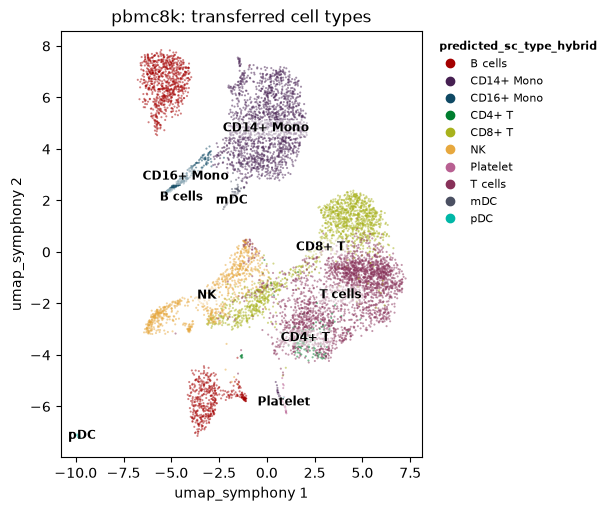

In [33]:
ax = bv.pl.embedding_plot(
    sc_query,
    "umap_symphony",
    "predicted_sc_type_hybrid",
    label_by="predicted_sc_type_hybrid",
    discrete=True,
)
ax.set_title("pbmc8k: transferred cell types")
plt.show()

Same UMAP, coloured by transfer confidence. Cells in the interior of their
cell type sit at confidence 1; cells on cluster boundaries or in cell types
poorly represented in the reference are the ones to scrutinise.

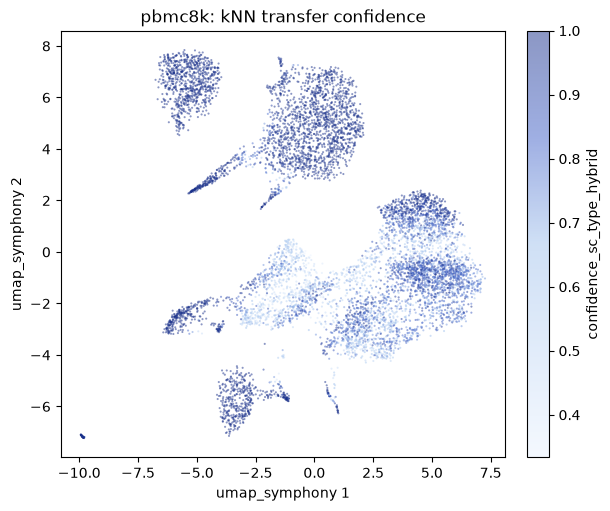

In [34]:
ax = bv.pl.embedding_plot(
    sc_query,
    "umap_symphony",
    "confidence_sc_type_hybrid",
    discrete=False,
)
ax.set_title("pbmc8k: kNN transfer confidence")
plt.show()

And a per-cell-type confidence distribution, useful for spotting cell types
where the reference and query disagree systematically:

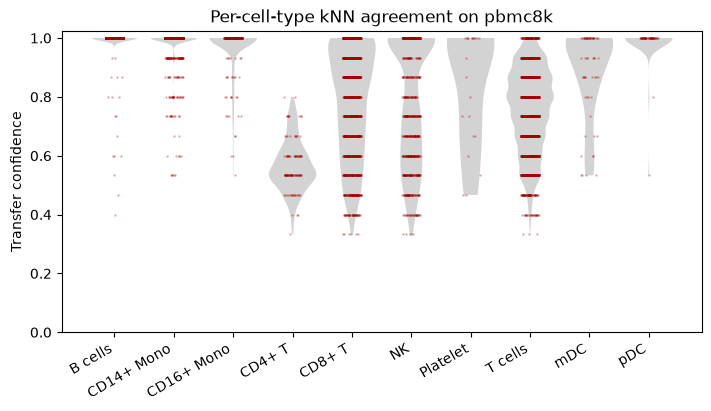

In [35]:
conf_df = (
    sc_query.obs(
        cols=["predicted_sc_type_hybrid", "confidence_sc_type_hybrid"], filtered=True
    )
    .drop_nulls("predicted_sc_type_hybrid")
    .sort("predicted_sc_type_hybrid")
)
groups = conf_df.partition_by("predicted_sc_type_hybrid", maintain_order=True)
cell_types = [g["predicted_sc_type_hybrid"][0] for g in groups]
values = [g["confidence_sc_type_hybrid"].to_numpy() for g in groups]

rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
parts = ax.violinplot(values, showextrema=False, widths=0.8)
for body in parts["bodies"]:
    body.set_facecolor("lightgrey")
    body.set_alpha(1)
for i, v in enumerate(values, start=1):
    ax.scatter(
        i + rng.uniform(-0.15, 0.15, v.size),
        v,
        s=1,
        alpha=0.2,
        color=bv.pl.bx_colors("main", n=1)[0],
    )
ax.set_xticks(range(1, len(cell_types) + 1), cell_types, rotation=30, ha="right")
ax.set_ylim(0, 1.025)
ax.set_ylabel("Transfer confidence")
ax.set_title("Per-cell-type kNN agreement on pbmc8k")
plt.show()

Sanity check of the transferred labels with the canonical markers:

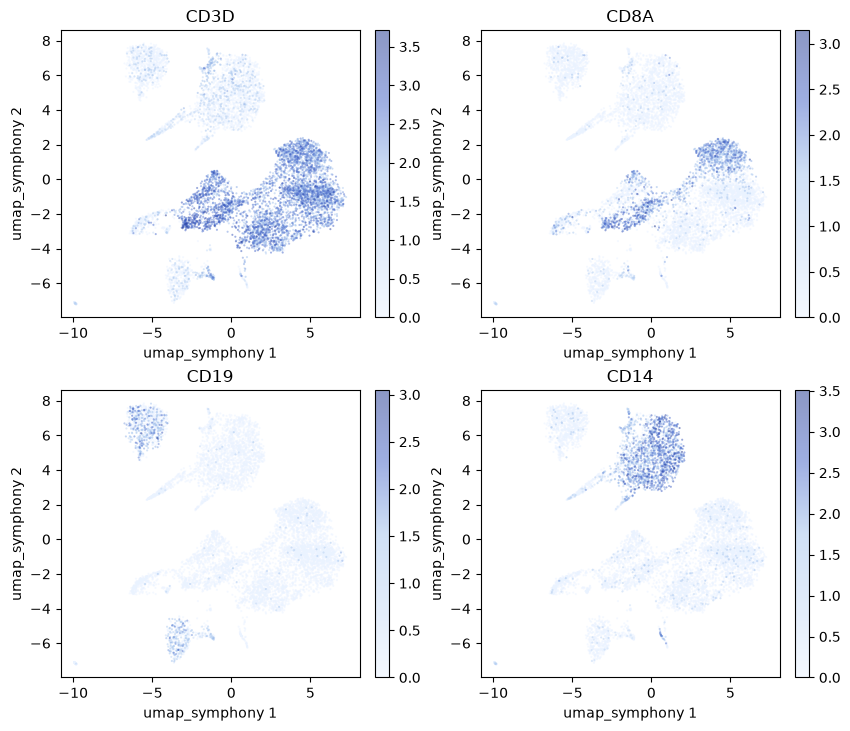

In [36]:
bv.pl.feature_plot(
    sc_query,
    list(canonical_markers),
    "umap_symphony",
    feature_labels=canonical_markers,
)
plt.show()

### Slim references and post-hoc labels

The reference above stores `z_corr`, `z_orig`, the soft cluster assignments
`r` and the labels. For large references that get checked into shared
storage, `z_orig` and `r` are dead weight; passing `slim=True` at build time
drops them. `z_corr` is always retained, since kNN label transfer searches
against it.

If you want to add or update labels after the reference is built (say, you
re-ran scType with a different marker set), use `add_symphony_labels()`. It
reads obs columns from a `SingleCells` object in `cells_to_keep` order and
snapshots them into a new reference (the input is left alone). The
`cells_to_keep` state must match the reference; the function errors if the
row count drifts.

```python
slim_ref = bv.annotate.build_symphony_ref(
    sc_ref,
    "exp_id",
    hvg_indices,
    harmony_params=HarmonyV2Params(),
    no_pcs=30,
    slim=True,
)

slim_ref = bv.annotate.add_symphony_labels(slim_ref, sc_ref, ["sc_type"])
```

Multiple label columns can be attached at once, existing columns are
protected unless you pass `overwrite=True`, and
`bv.annotate.get_symphony_labels(reference)` returns the stored DataFrame (or
`None` if there is none). `save_symphony_ref()` and `load_symphony_ref()` write
the reference to a single `.npz` and back.

## Clean up

In [37]:
tempdir_ref.cleanup()
tempdir_query.cleanup()